# Data Processing and Cleaning
This notebook contains the steps to inspect, clean, and preprocess the data associated with the GSE2034 breast cancer dataset. This notebook will review the gene expression dataset, clinical parameter dataset, and the signaling processing data (ABS and p-value data) that will be used to remove weak signal data from the final dataset. <br>
This is the first step in getting set up to run this project. 

## Import, verification and inspection of raw data
Since the clinical data (like ER status, relapse status, lymph node status) is being pulled from the GEO Omnibus, it must be converted into a format that is machine readable. When downloading from the source, it downloads as a txt. This section below formats the txt into a dataframe. It also renames some of the key column headers, so that they will match the other data files.
### Results Review
The expression matrix, ABS detection, P-value detection and clinical parameters dataset do not have any missing information. <br>
The annotation dataset has some missing values. the most important to note for this project are:


*   Gene Title
*   Gene Symbol



In [1]:
import os

print("Current working directory:", os.getcwd())
print("Files in current directory:", os.listdir())

Current working directory: c:\Users\Sara\Documents\CIND820\gse2034-research-dashboard\analysis
Files in current directory: ['01_rma_preprocessing.R', '02_preprocessing_data.ipynb', '03_exploratory_report.ipynb', '04_machine_learning.ipynb']


In [2]:
'''Converting Clinical Data txt file into dataframe'''
#Some columns of interest will be renamed, to make it easier to reference them later.

import pandas as pd
import matplotlib.pyplot as plt
clinical_data = pd.read_csv('../data/clinical_data.txt', sep="\t")
#print (clinical_data)
clinical_parameters_df = pd.DataFrame(clinical_data)
'''renaming the column names to avoid any special character issues down the line'''
clinical_parameters_df.rename(columns={"GEO asscession number":"Sample_Accession", 
                                       "time to relapse or last follow-up (months)":"Follow_up_months", 
                                       "relapse (1=True)":"Relapse", "ER Status":"ER_status"},inplace=True)
print (clinical_parameters_df)
print ('\nCount of NaN in each column:\n', clinical_parameters_df.isnull().sum())

     PID Sample_Accession lymph node status  Follow_up_months  Relapse  \
0      3         GSM36793          negative               101        0   
1      5         GSM36796          negative               118        0   
2      6         GSM36797          negative                 9        1   
3      7         GSM36798          negative               106        0   
4      8         GSM36800          negative                37        1   
..   ...              ...               ...               ...      ...   
281  900         GSM36887          negative               108        0   
282  901         GSM36889          negative               108        0   
283  903         GSM36892          negative               110        0   
284  909         GSM36894          negative               109        0   
285  913         GSM36911          negative                80        1   

    ER_status  Brain relapses (1=yes, 0=no)  
0         ER-                             0  
1         ER+      

#### Verifying Gene Expression Data
The gene expression dataset has been pulled from Kaggle. The same dataset can be found on Geo Omnibus as well. The Kaggle dataset is said to be 'normalized' however normalization methods are not verifiable. This code block (and the code block below) are working to verify the differences between the two datasets, in order to reverse engineer what (if any) normalization methods have been applied to the Kaggle dataset. <br>
This code block confirms that the two datasets are the exact same, and the only normalization methods performed on the gene expression is Image was globally scaled to a target intensity of 600 (standard microarray analysis procedure)

In [3]:
'''Checking to see if the GEO Omnbibus is the same as the Kaggle. Importing the Geo Omnbinus and sorting it by ID_Ref so that this dataframe and the kaggle one can be properly compared'''
# The gene expression dataset has been pulled from Kaggle. The same dataset can be found on Geo Omnibus as well. The Kaggle dataset is said to be 'normalized' however normalization methods are not verifiable. This code block (and the code block below) are working to verify the differences between the two datasets, in order to reverse engineer what (if any) normalization methods have been applied to the Kaggle dataset.

geo_gene = pd.read_csv('../data/GSE2034_series_matrix.txt', sep="\t")
descending_geo_gene_df = pd.DataFrame(geo_gene)
geo_gene_df = descending_geo_gene_df.sort_values(by='ID_REF', ascending=False, ignore_index=True)
#print (geo_gene_df)

geo_gene_df.head(10)
#print ('\nCount of NaN in each column:\n', geo_gene_df.isnull().sum())


,ID_REF,GSM36777,GSM36778,GSM36779,GSM36780,GSM36781,GSM36782,GSM36783,GSM36784,GSM36785,...,GSM37053,GSM37054,GSM37055,GSM37056,GSM37057,GSM37058,GSM37059,GSM37060,GSM37061,GSM37062
0,AFFX-r2-P1-cre-5_at,25644.4,40720.0,50878.7,46870.8,40847.1,38321.7,38065.4,61162.1,22337.5,...,115944.2,66109.4,68767.8,49943.9,56631.2,43122.0,39033.8,58585.2,38360.8,30222.1
1,AFFX-r2-P1-cre-3_at,33168.9,54401.4,61244.1,62292.1,57295.1,50074.6,46900.9,78481.5,29587.9,...,146868.8,85468.0,87049.5,62343.2,70987.3,57830.1,50140.4,69320.3,48495.6,38260.2
2,AFFX-r2-Hs28SrRNA-M_at,661.5,716.1,1189.3,801.1,191.1,257.2,117.8,411.1,246.4,...,826.8,321.4,882.5,429.5,740.4,444.5,330.3,532.4,188.0,642.4
3,AFFX-r2-Hs28SrRNA-5_at,619.9,511.3,1618.4,780.5,276.0,277.8,251.1,489.4,311.5,...,1736.3,479.3,1223.0,602.3,713.5,346.6,538.9,425.5,247.5,648.3
4,AFFX-r2-Hs28SrRNA-3_at,1920.8,725.2,4172.0,1881.9,435.8,703.4,393.6,850.1,533.4,...,3724.6,917.1,3250.3,487.1,822.7,842.8,619.6,1113.8,498.8,1105.5
5,AFFX-r2-Hs18SrRNA-M_x_at,737.5,822.2,2724.6,757.8,114.3,237.5,239.6,368.7,227.4,...,1400.2,271.5,1516.4,656.0,715.2,302.4,429.1,456.1,274.0,758.3
6,AFFX-r2-Hs18SrRNA-5_at,1093.1,467.9,3118.9,664.8,27.2,187.9,113.4,374.4,124.2,...,1293.8,253.6,1126.5,286.2,607.6,361.6,231.1,322.5,136.7,547.0
7,AFFX-r2-Hs18SrRNA-3_s_at,1192.4,1010.5,3567.7,1582.9,420.1,568.1,348.6,954.3,536.0,...,2886.8,906.7,2170.3,1242.3,1156.7,813.9,682.1,1091.1,258.0,1188.9
8,AFFX-r2-Ec-bioD-5_at,5865.6,9912.1,13108.1,9052.7,9722.1,10466.5,10771.4,15028.7,6278.4,...,35946.6,18063.0,22226.3,12449.5,16209.5,12475.0,10182.5,14860.8,10492.6,7278.3
9,AFFX-r2-Ec-bioD-3_at,6289.8,11238.1,12469.8,9050.9,8562.3,10090.0,9569.2,12521.8,5830.4,...,30129.7,17034.5,20820.7,11789.4,16696.2,12107.7,10330.5,15805.0,9545.9,7032.6


In [4]:
'''Convert Expression Matrix into Dataframe'''

gene_seq_data = pd.read_csv('../data/GSE2034_family_expression_matrix.csv', sep=",")
non_log_gene_seq_df = pd.DataFrame(gene_seq_data)
as_gene_seq_df = non_log_gene_seq_df.sort_values(by='ID_REF', ascending=False, ignore_index=True)
#print (as_gene_seq_df)
as_gene_seq_df.head(10)
#print ('\nCount of NaN in each column:\n', gene_seq_df.isnull().sum())

,ID_REF,GSM36777,GSM36778,GSM36779,GSM36780,GSM36781,GSM36782,GSM36783,GSM36784,GSM36785,...,GSM37053,GSM37054,GSM37055,GSM37056,GSM37057,GSM37058,GSM37059,GSM37060,GSM37061,GSM37062
0,AFFX-r2-P1-cre-5_at,25644.4,40720.0,50878.7,46870.8,40847.1,38321.7,38065.4,61162.1,22337.5,...,115944.2,66109.4,68767.8,49943.9,56631.2,43122.0,39033.8,58585.2,38360.8,30222.1
1,AFFX-r2-P1-cre-3_at,33168.9,54401.4,61244.1,62292.1,57295.1,50074.6,46900.9,78481.5,29587.9,...,146868.8,85468.0,87049.5,62343.2,70987.3,57830.1,50140.4,69320.3,48495.6,38260.2
2,AFFX-r2-Hs28SrRNA-M_at,661.5,716.1,1189.3,801.1,191.1,257.2,117.8,411.1,246.4,...,826.8,321.4,882.5,429.5,740.4,444.5,330.3,532.4,188.0,642.4
3,AFFX-r2-Hs28SrRNA-5_at,619.9,511.3,1618.4,780.5,276.0,277.8,251.1,489.4,311.5,...,1736.3,479.3,1223.0,602.3,713.5,346.6,538.9,425.5,247.5,648.3
4,AFFX-r2-Hs28SrRNA-3_at,1920.8,725.2,4172.0,1881.9,435.8,703.4,393.6,850.1,533.4,...,3724.6,917.1,3250.3,487.1,822.7,842.8,619.6,1113.8,498.8,1105.5
5,AFFX-r2-Hs18SrRNA-M_x_at,737.5,822.2,2724.6,757.8,114.3,237.5,239.6,368.7,227.4,...,1400.2,271.5,1516.4,656.0,715.2,302.4,429.1,456.1,274.0,758.3
6,AFFX-r2-Hs18SrRNA-5_at,1093.1,467.9,3118.9,664.8,27.2,187.9,113.4,374.4,124.2,...,1293.8,253.6,1126.5,286.2,607.6,361.6,231.1,322.5,136.7,547.0
7,AFFX-r2-Hs18SrRNA-3_s_at,1192.4,1010.5,3567.7,1582.9,420.1,568.1,348.6,954.3,536.0,...,2886.8,906.7,2170.3,1242.3,1156.7,813.9,682.1,1091.1,258.0,1188.9
8,AFFX-r2-Ec-bioD-5_at,5865.6,9912.1,13108.1,9052.7,9722.1,10466.5,10771.4,15028.7,6278.4,...,35946.6,18063.0,22226.3,12449.5,16209.5,12475.0,10182.5,14860.8,10492.6,7278.3
9,AFFX-r2-Ec-bioD-3_at,6289.8,11238.1,12469.8,9050.9,8562.3,10090.0,9569.2,12521.8,5830.4,...,30129.7,17034.5,20820.7,11789.4,16696.2,12107.7,10330.5,15805.0,9545.9,7032.6


In [5]:
as_gene_seq_df.equals(geo_gene_df)

True

#### Analysing the Gene Expression Dataset
This code block visualizes the gene expression data to answer whether we should perform any normalization procedures on the data. <br>
We see a very heavy right skew in the distribution. Utilizing log2 as a transformation technique, we see a more normal shaped distribution across the values. <br>
RMA (Robust Multi-array Average) is the standard normalization technique in micro array data. There are robust R packages that can perform this, which we will incorporate to normalize our data. 

In [6]:
'''Making a df without the ID_REF so we can check the distribution and also log just the numerical values'''
expression_df = non_log_gene_seq_df.iloc[:, 1:]

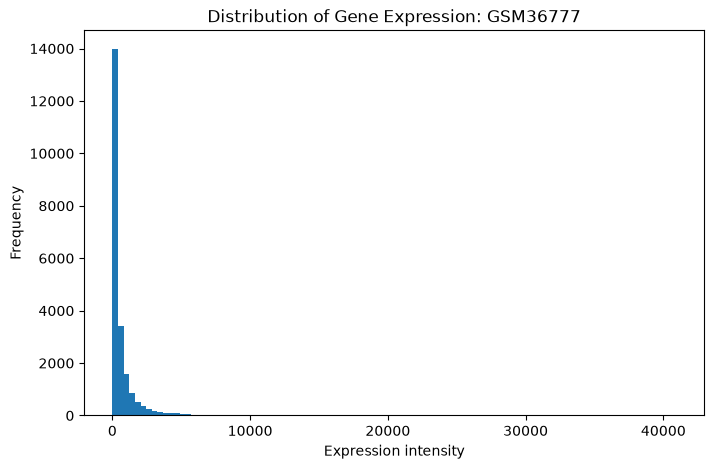

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(expression_df["GSM36777"], bins=100)
plt.xlabel("Expression intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Gene Expression: GSM36777")
plt.show()

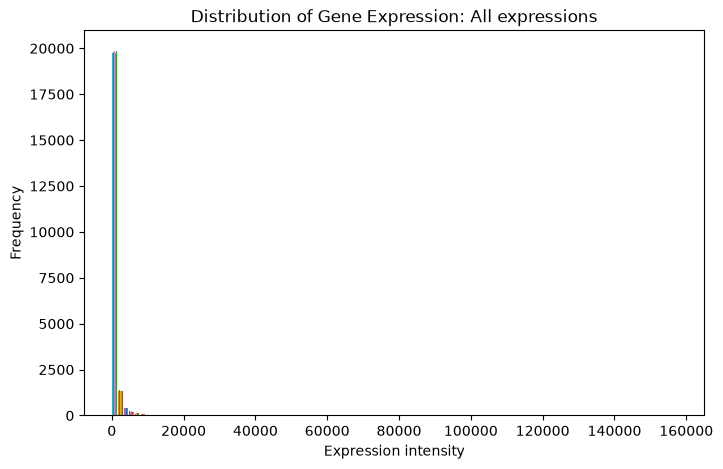

In [8]:
# All distribution, not logged

plt.figure(figsize=(8, 5))
plt.hist(expression_df, bins=100)
plt.xlabel("Expression intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Gene Expression: All expressions")
plt.show()

#### RMA from R 
In the R script within this project folder, we have conducted the RMA normalization using R packages. The script outputs a csv file that will be saved in this repository. This step is looking to make sure that the csv produced is as expected (sample IDs, probeIDs, and any other formatting that needs to be double checked)

In [9]:
'''After the R package runs the RMA preprocessing and exports the values into a csv, let's check the csv and make sure all samples and probeIDs match what we are expecting'''

rma_data = pd.read_csv('../data/processed/GSE2034_RMA_expression.csv', sep=",",index_col=0)
rma_data_df = pd.DataFrame(rma_data)

#rma_data_df= rma_data_df.rename(columns={"Unnamed: 0": "ID_REF"})

rma_data_df.head(10)

#print(expression_df.shape)
#print(expression_df.dtypes.value_counts())
#print(expression_df.iloc[:5, :5])
#rma_data_df.columns.values.tolist()


,ID_REF,GSM36777,GSM36778,GSM36779,GSM36780,GSM36781,GSM36782,GSM36783,GSM36784,GSM36785,...,GSM37053,GSM37054,GSM37055,GSM37056,GSM37057,GSM37058,GSM37059,GSM37060,GSM37061,GSM37062
1,1007_s_at,10.656269,10.826179,11.126097,10.477855,10.582677,10.399324,10.989782,10.655691,10.499938,...,10.441638,10.555977,10.268948,9.941358,10.634577,10.403816,10.237851,10.105363,10.569942,10.064402
2,1053_at,6.293524,6.105409,6.239484,6.628975,6.699766,6.315661,6.406297,6.205352,6.394677,...,6.439670,6.654475,6.363508,6.277242,5.953627,6.408306,6.147732,6.243020,6.410304,6.435854
3,117_at,6.785154,6.446397,6.779564,6.673216,6.682278,6.317047,6.382554,6.466162,6.675949,...,7.028234,6.426169,7.046704,6.429268,6.647153,6.529079,6.478356,6.510223,6.320532,6.402398
4,121_at,8.147451,8.757778,8.530315,8.499970,8.374228,8.378569,8.531411,8.719074,8.437974,...,8.039196,8.500090,8.230137,8.345502,8.323438,8.435767,8.317712,8.514075,8.519920,8.354594
5,1255_g_at,4.096793,4.303505,4.028836,4.244533,4.175736,4.124281,4.123749,4.208563,4.226815,...,4.457992,4.061280,4.119207,4.094743,4.144623,4.069354,4.096460,4.246337,4.067051,4.249217
6,1294_at,8.116105,8.046588,8.072878,7.719168,7.990972,7.886824,7.892833,7.959077,7.663512,...,7.692603,7.464453,7.584663,8.117342,7.989336,8.072817,8.158587,7.797678,7.751808,7.392361
7,1316_at,5.543389,5.858173,5.518387,5.735773,5.629806,5.488902,5.372090,5.815622,5.472751,...,5.650518,5.613513,6.108775,5.770345,5.537505,5.252164,5.469952,5.656893,5.450313,5.564115
8,1320_at,4.516934,4.785831,4.698010,4.926212,4.557316,4.621336,4.554467,4.751279,4.600456,...,4.610898,4.637658,4.636493,4.689384,4.608098,4.701579,4.628598,4.847483,4.773421,4.663132
9,1405_i_at,6.297705,6.626540,5.466980,7.427322,9.247610,5.536916,5.429129,6.690181,5.216600,...,6.772601,5.708795,5.882321,6.632790,4.776155,6.840736,7.284411,6.493873,5.064468,6.542987
10,1431_at,3.841181,4.005531,4.009299,4.086284,4.145742,4.225975,3.952046,4.076595,3.917960,...,3.999300,4.047444,3.946082,4.044730,3.901070,3.899656,4.052792,3.945380,4.104515,4.039514


In [11]:
'''Putting column names (the sample ids) and first column values (ID REF) in two lists, will sort them alpha, and compare to gene expression df above'''

headers_rma = sorted(rma_data_df.columns.values.tolist())

id_ref_rma= sorted(rma_data_df['ID_REF'].tolist())

headers_kaggle = sorted(as_gene_seq_df.columns.values.tolist())

id_ref_kaggle = sorted(as_gene_seq_df['ID_REF'].tolist())

print (headers_rma)
print (id_ref_rma)

print (headers_kaggle)
print (id_ref_kaggle)

# checking to see if the sorted headers and ID ref column are equal
headers_rma == headers_kaggle
id_ref_rma == id_ref_kaggle

['GSM36777', 'GSM36778', 'GSM36779', 'GSM36780', 'GSM36781', 'GSM36782', 'GSM36783', 'GSM36784', 'GSM36785', 'GSM36786', 'GSM36787', 'GSM36788', 'GSM36789', 'GSM36790', 'GSM36791', 'GSM36792', 'GSM36793', 'GSM36794', 'GSM36795', 'GSM36796', 'GSM36797', 'GSM36798', 'GSM36799', 'GSM36800', 'GSM36801', 'GSM36802', 'GSM36803', 'GSM36804', 'GSM36805', 'GSM36806', 'GSM36807', 'GSM36808', 'GSM36809', 'GSM36810', 'GSM36811', 'GSM36812', 'GSM36813', 'GSM36814', 'GSM36815', 'GSM36816', 'GSM36817', 'GSM36818', 'GSM36819', 'GSM36820', 'GSM36821', 'GSM36822', 'GSM36823', 'GSM36824', 'GSM36825', 'GSM36826', 'GSM36827', 'GSM36828', 'GSM36829', 'GSM36830', 'GSM36831', 'GSM36832', 'GSM36833', 'GSM36834', 'GSM36835', 'GSM36836', 'GSM36837', 'GSM36838', 'GSM36839', 'GSM36840', 'GSM36841', 'GSM36842', 'GSM36843', 'GSM36844', 'GSM36845', 'GSM36846', 'GSM36847', 'GSM36848', 'GSM36849', 'GSM36850', 'GSM36851', 'GSM36852', 'GSM36853', 'GSM36854', 'GSM36855', 'GSM36856', 'GSM36857', 'GSM36858', 'GSM36859', 'GS

True

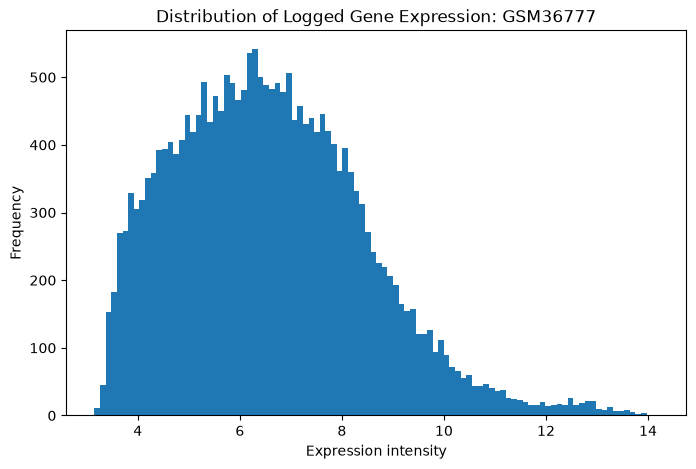

In [12]:
#Distribution of just 1 sample in log df
plt.figure(figsize=(8, 5))
plt.hist(rma_data_df["GSM36777"], bins=100)
plt.xlabel("Expression intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Logged Gene Expression: GSM36777")
plt.show()

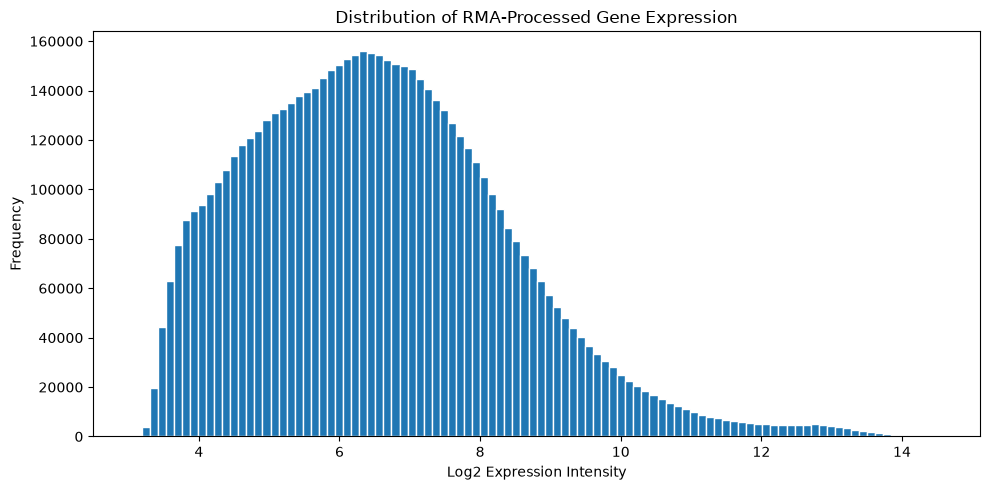

In [13]:
import matplotlib.pyplot as plt

all_numeric_rma = rma_data_df.drop(columns='ID_REF')

all_expression = all_numeric_rma.to_numpy().flatten()

plt.figure(figsize=(10, 5))

plt.hist(
    all_expression,
    bins=100,
    edgecolor="white"
)

plt.title("Distribution of RMA-Processed Gene Expression")
plt.xlabel("Log2 Expression Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

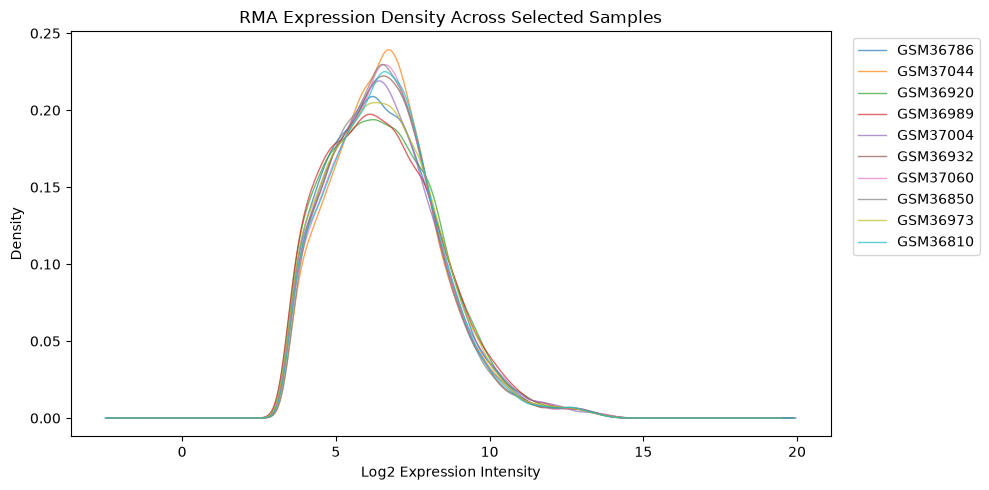

In [14]:
'''RMA contains quantile normalization, so lets compare distributions between the samples'''

import matplotlib.pyplot as plt

# Select 10 samples
sample_subset = all_numeric_rma.sample(
    n=10,
    axis=1,
    random_state=42
)

plt.figure(figsize=(10, 5))

for sample in sample_subset.columns:
    sample_subset[sample].plot(
        kind="kde",
        alpha=0.7,
        linewidth=1
    )

plt.title("RMA Expression Density Across Selected Samples")
plt.xlabel("Log2 Expression Intensity")
plt.ylabel("Density")
plt.legend(
    sample_subset.columns,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

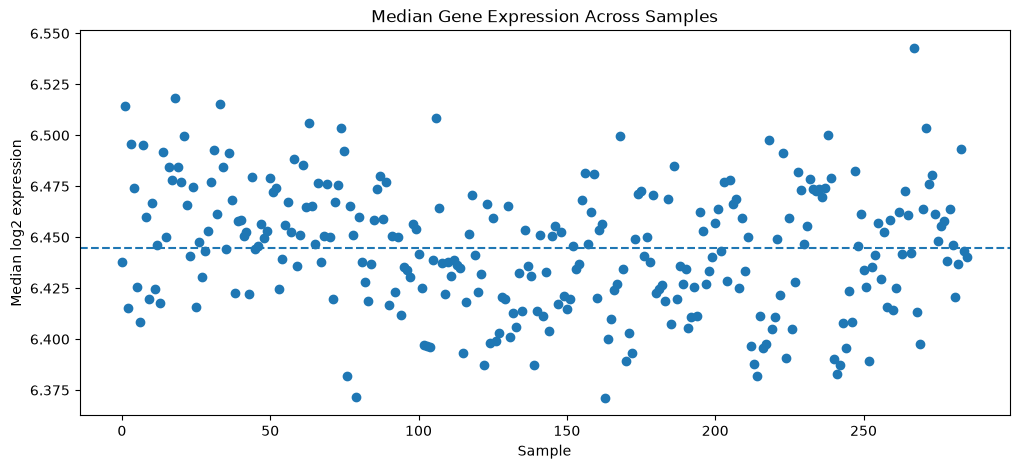

In [15]:
'''Checking Distribution of medians between all samples'''

import matplotlib.pyplot as plt

# Calculate median expression for each sample
sample_medians = all_numeric_rma.median()

# Calculate interquartile range for each sample
sample_iqr = (
    all_numeric_rma.quantile(0.75) -
    all_numeric_rma.quantile(0.25)
)

# Plot sample medians
plt.figure(figsize=(12, 5))
plt.scatter(range(len(sample_medians)), sample_medians)
plt.axhline(sample_medians.median(), linestyle="--")
plt.xlabel("Sample")
plt.ylabel("Median log2 expression")
plt.title("Median Gene Expression Across Samples")
plt.show()

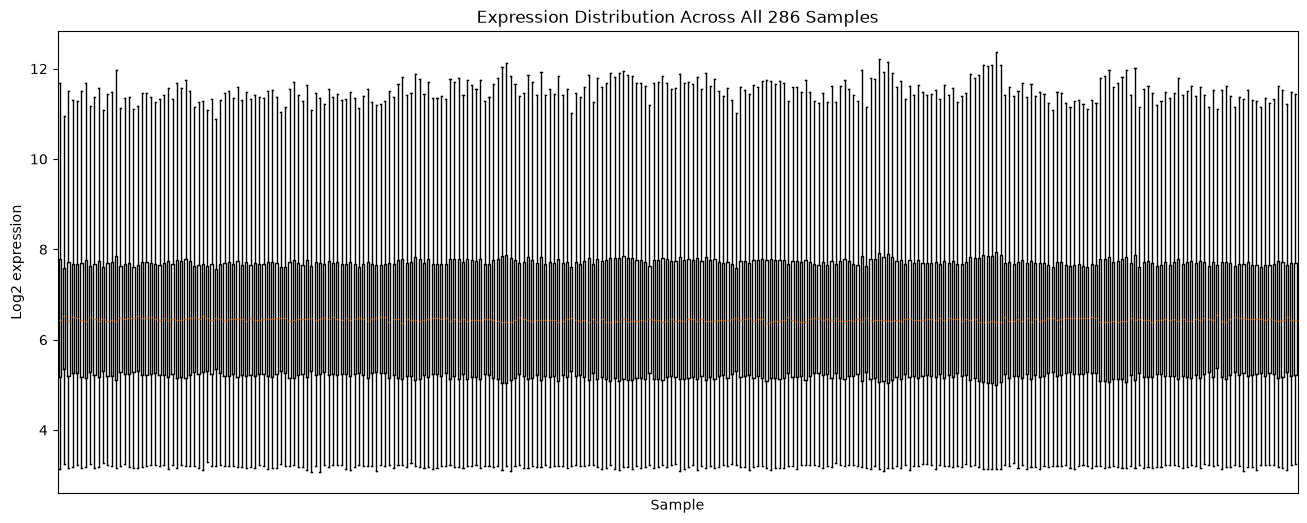

In [16]:
'''Checking full distribution using boxplots'''

plt.figure(figsize=(16, 6))

plt.boxplot(
    all_numeric_rma,
    showfliers=False
)

plt.xlabel("Sample")
plt.ylabel("Log2 expression")
plt.title("Expression Distribution Across All 286 Samples")
plt.xticks([])
plt.show()

## Inspecting ABS and P value data for the signal intensity, and creating parameters to filter weak signals from the dataset

In [17]:
'''Convert ABS DETECTION data file into dataframe'''

PAM_data= pd.read_csv('../data/GSE2034_family_matrix_ABS_CALL.csv', sep=",")
PAM_data_df = pd.DataFrame(PAM_data)
print (PAM_data_df)

print ('\nCount of NaN in each column:\n', PAM_data_df.isnull().sum())

               ID_REF GSM36777 GSM36778 GSM36779 GSM36780 GSM36781 GSM36782  \
0      AFFX-BioB-5_at        P        P        P        P        P        P   
1      AFFX-BioB-M_at        P        P        P        P        P        P   
2      AFFX-BioB-3_at        P        P        P        P        P        P   
3      AFFX-BioC-5_at        P        P        P        P        P        P   
4      AFFX-BioC-3_at        P        P        P        P        P        P   
...               ...      ...      ...      ...      ...      ...      ...   
22278     222380_s_at        P        P        P        P        P        P   
22279       222381_at        A        A        A        A        A        A   
22280     222382_x_at        A        A        A        P        A        A   
22281     222383_s_at        A        A        A        A        A        A   
22282       222384_at        A        A        A        A        A        A   

      GSM36783 GSM36784 GSM36785  ... GSM37053 GSM3

In [18]:
'''Convert Detection P-value file into dataframe'''
P_data= pd.read_csv('../data/GSE2034_family_matrix_DETECTION_P_VALUE.csv', sep=",")
P_data_df = pd.DataFrame(P_data)
print (P_data_df)

print ('\nCount of NaN in each column:\n', P_data_df.isnull().sum())

               ID_REF  GSM36777  GSM36778  GSM36779  GSM36780  GSM36781  \
0      AFFX-BioB-5_at  0.002023  0.001248  0.000390  0.000972  0.001593   
1      AFFX-BioB-M_at  0.000081  0.000044  0.000044  0.000052  0.000095   
2      AFFX-BioB-3_at  0.000195  0.000052  0.000052  0.000060  0.000127   
3      AFFX-BioC-5_at  0.000127  0.000110  0.000081  0.000110  0.000195   
4      AFFX-BioC-3_at  0.000070  0.000081  0.000070  0.000070  0.000060   
...               ...       ...       ...       ...       ...       ...   
22278     222380_s_at  0.000732  0.000244  0.030273  0.000732  0.000732   
22279       222381_at  0.334473  0.219482  0.111572  0.111572  0.303711   
22280     222382_x_at  0.129639  0.303711  0.171387  0.030273  0.095215   
22281     222383_s_at  0.500000  0.533936  0.919434  0.780518  0.665527   
22282       222384_at  0.067627  0.432373  0.246094  0.432373  0.423828   

       GSM36782  GSM36783  GSM36784  GSM36785  ...  GSM37053  GSM37054  \
0      0.000446  0.000509

In [19]:
'''inspect master file for any missing values'''
import numpy as np

missing_values_master = rma_data_df.isnull().any(axis=1).sum()
missing_values_PAM = PAM_data_df.isnull().any(axis=1).sum()
missing_values_P = P_data_df.isnull().any(axis=1).sum()

print ("Number of missing data in Master File:", missing_values_master)
print ("Number of missing data in PAM File:", missing_values_PAM)
print ("Number of missing data in P-value File:", missing_values_P)

Number of missing data in Master File: 0
Number of missing data in PAM File: 0
Number of missing data in P-value File: 0


In [20]:
'''Investigating shapes of 3 dataframes'''

print ("Shape of gene_seq_df:", rma_data_df.shape)
print ("Shape of PAM_data_df:", PAM_data_df.shape)
print ("Shape of P_data_df:", P_data_df.shape)

Shape of gene_seq_df: (22283, 287)
Shape of PAM_data_df: (22283, 287)
Shape of P_data_df: (22283, 287)


In [21]:
'''Putting Headers in a list to compare'''

master_headers = list(rma_data_df.columns.values)
PAM_headers = list(PAM_data_df.columns.values)
P_headers = list(P_data_df.columns.values)


'''Testing to see if the lists are identical'''

master_vs_PAM = master_headers == PAM_headers
master_vs_P = master_headers == P_headers

print ("Is Master Header Identical to PAM header:", master_vs_PAM)
print ("Is Master Header Identical to P header:", master_vs_P)


'''Putting values of first column (Probe ID's) in a list to compare'''

master_ProbeID = sorted(rma_data_df['ID_REF'].values.tolist())
PAM_ProbeID = sorted(PAM_data_df['ID_REF'].values.tolist())
P_ProbeID = sorted(P_data_df['ID_REF'].values.tolist())

'''Comparing Master first column to PAM and Pvalue'''


#print (master_ProbeID)
#print(PAM_ProbeID)
master_probe_pam = master_ProbeID == PAM_ProbeID
master_probe_p = master_ProbeID == P_ProbeID

print ("Is Master ProbeID Identical to PAM ProbID:", master_probe_pam)
print ("Is Master ProbID Identical to P ProbID:", master_probe_p)

Is Master Header Identical to PAM header: True
Is Master Header Identical to P header: True
Is Master ProbeID Identical to PAM ProbID: True
Is Master ProbID Identical to P ProbID: True


In [22]:
'''Convert Gene Annotation File into dataframe'''

annotation_data = pd.read_csv('../data/GSE2034_family_platform_GPL96_annotation.csv', sep=",")
annotation_data_df = pd.DataFrame(annotation_data)
print (annotation_data_df)

print ('\nCount of NaN in each column:\n', annotation_data_df.isnull().sum())

                    ID  GB_ACC    SPOT_ID Species Scientific Name  \
0            1007_s_at  U48705        NaN            Homo sapiens   
1              1053_at  M87338        NaN            Homo sapiens   
2               117_at  X51757        NaN            Homo sapiens   
3               121_at  X69699        NaN            Homo sapiens   
4            1255_g_at  L36861        NaN            Homo sapiens   
...                ...     ...        ...                     ...   
22278   AFFX-ThrX-5_at     NaN  --Control            Homo sapiens   
22279   AFFX-ThrX-M_at     NaN  --Control            Homo sapiens   
22280  AFFX-TrpnX-3_at     NaN  --Control            Homo sapiens   
22281  AFFX-TrpnX-5_at     NaN  --Control            Homo sapiens   
22282  AFFX-TrpnX-M_at     NaN  --Control            Homo sapiens   

      Annotation Date      Sequence Type                  Sequence Source  \
0         Oct 6, 2014  Exemplar sequence  Affymetrix Proprietary Database   
1         Oct 6, 

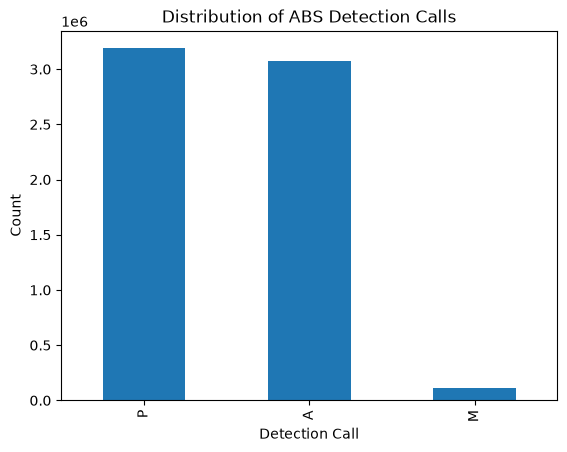


 Number of values by Type:
 P    3187954
A    3076782
M     108202
Name: count, dtype: int64

 Percentage of detections marked Present:

P: 50.02 %
A: 48.28 %
M: 1.7 %


In [23]:
'''ABS Detection Distribution'''
#Distribution of how many values are marked Present vs Absent vs Marginal
PAM_values = PAM_data_df.iloc[:,1:]

call_counts=PAM_values.stack().value_counts()

call_counts.plot(kind='bar')
plt.xticks(rotation=90)
plt.ylabel("Count")
plt.xlabel("Detection Call")
plt.title("Distribution of ABS Detection Calls")

plt.show()

'''Distributions by Number'''
p_percent = round((call_counts.get('P',0)/ PAM_values.size)*100, 2)
a_percent = round((call_counts.get('A',0)/ PAM_values.size)*100, 2)
m_percent = round((call_counts.get('M',0)/ PAM_values.size)*100, 2)

print ('\n Number of values by Type:\n', call_counts)
print ('\n Percentage of detections marked Present:\n')
print ('P:', p_percent, '%')
print ('A:', a_percent, '%')
print ('M:', m_percent, '%')


In [24]:
''' How many ProbeID rows are CONSISTENTLY marked Present'''
pam_value_row = PAM_data_df.iloc[:,1:]

#how many samples in each row are marked present. The output will be a value
#between 0 to 1. 0 = no values in the row marked present
# 1 = all values in the row not marked present

present_detection_rate = (pam_value_row == 'P').mean(axis = 1)

#summarizing

present_detection_summary = pd.DataFrame ( {
    'ID_REF': PAM_data_df.iloc[:,0],
    'Detection_Rate' : present_detection_rate.values
})


print (present_detection_summary)

#print (p_value_row.shape, p_value_row.dtypes.value_counts())

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22278     222380_s_at        0.996503
22279       222381_at        0.062937
22280     222382_x_at        0.300699
22281     222383_s_at        0.003497
22282       222384_at        0.000000

[22283 rows x 2 columns]


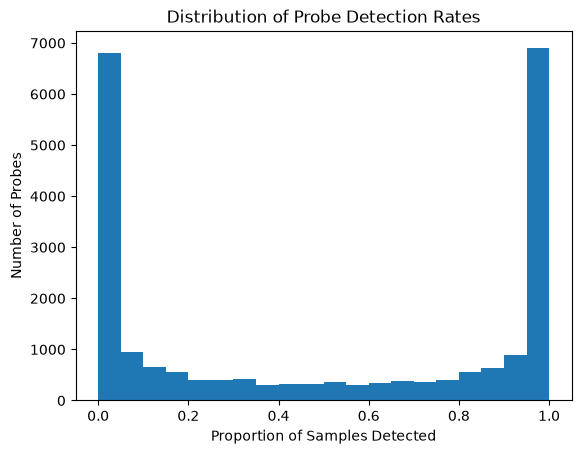

In [25]:
'''Visualizing detection rates in histogram'''

plt.hist(present_detection_summary['Detection_Rate'], bins =20)

plt.ylabel("Number of Probes")
plt.xlabel("Proportion of Samples Detected")
plt.title("Distribution of Probe Detection Rates")

plt.show()


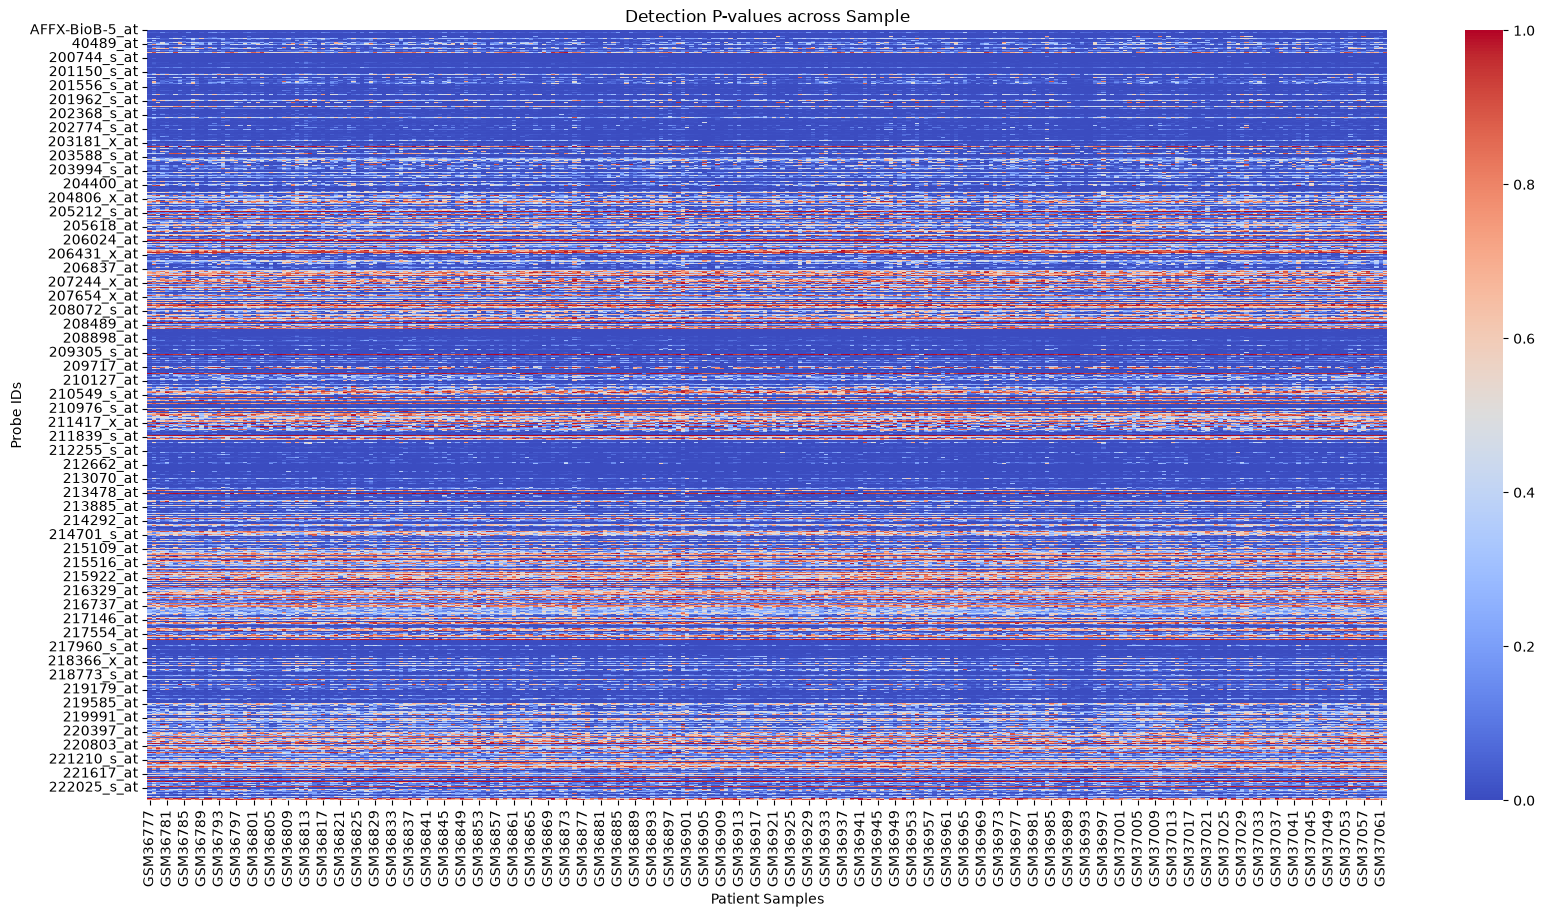

In [26]:
'''P-value Distribution'''
#Using a heat map will allow for easy spotting of probe IDs that are
#reliably meeting the p-value threshold, and ones that are not meeting
#the p-value threshold.

import seaborn as sns

P_values = P_data_df.set_index('ID_REF')

#sample_probes = P_values.sample(n=100, random_state=42)
plt.figure(figsize=(20,10))

sns.heatmap(
    P_values,
    cmap='coolwarm',
    vmin=0,
    vmax=1
)

plt.ylabel("Probe IDs")
plt.xlabel("Patient Samples")
plt.title("Detection P-values across Sample")

plt.show()

In [27]:
''' How many Probes are CONSISTENTLY 'reliable' at detecting signal'''
p_value_row = P_data_df.iloc[:,1:]

#how many samples in each row met the threshold. The output will be a value
#between 0 to 1. 0 = no values in the row meet the threshold
# 1 = all values in the row meet the threshold

detection_rate = (p_value_row < 0.05).mean(axis = 1)

#summarizing

detection_summary = pd.DataFrame ( {
    'ID_REF': P_data_df.iloc[:,0],
    'Detection_Rate' : detection_rate.values
})

print (detection_summary)

print (p_value_row.shape, p_value_row.dtypes.value_counts())

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22278     222380_s_at        0.996503
22279       222381_at        0.062937
22280     222382_x_at        0.300699
22281     222383_s_at        0.003497
22282       222384_at        0.000000

[22283 rows x 2 columns]
(22283, 286) float64    286
Name: count, dtype: int64


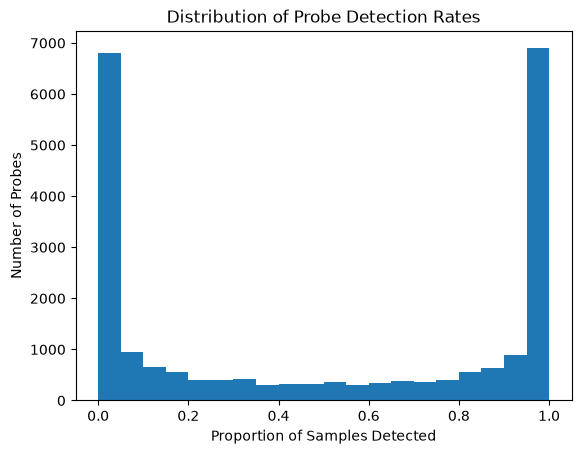

In [28]:
'''Visualizing detection rates in histogram'''

plt.hist(detection_summary['Detection_Rate'], bins =20)

plt.ylabel("Number of Probes")
plt.xlabel("Proportion of Samples Detected")
plt.title("Distribution of Probe Detection Rates")

plt.show()

## Filtering Unreliable ProbeIDs
We have a distribution of how proportionally reliable each ProbeID is. The next step is filtering out the probeIDs that produce very weak/unrealible signals. There are various methodologies for filtering the low signal ProbeIDs. One paper cited success in filtering out ProbeIDs that have less than 50% 'Present' marked values in the row. I will employ this method for the ABS data, and also for the p-value data. And compare the results.

##Results

Both filtering methods had the same result. Both filtered down to 11,130 rows. This is consistent with what was shown in the previous analysis, where it seems the data was split almost in half, with half the Probes appearing to show strong signal, the other half appearing to show very weak signal.

In [29]:
'''Filter out ProbeIDs that have a detection rate of less than 0.5 from PAM'''

filtered_present_detection_df = present_detection_summary.loc[present_detection_summary['Detection_Rate'] >= 0.5, ['ID_REF', 'Detection_Rate']]

print (filtered_present_detection_df)

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22268     222370_x_at        0.905594
22269       222371_at        0.849650
22274       222376_at        0.856643
22277       222379_at        0.667832
22278     222380_s_at        0.996503

[11130 rows x 2 columns]


In [30]:
'''Filter out ProbeIDs that have a detection rate of less than 0.5 from P-value'''

filtered_p_detection_df = detection_summary.loc[detection_summary['Detection_Rate'] >= 0.5, ['ID_REF', 'Detection_Rate']]

print (filtered_p_detection_df)

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22268     222370_x_at        0.905594
22269       222371_at        0.849650
22274       222376_at        0.856643
22277       222379_at        0.667832
22278     222380_s_at        0.996503

[11130 rows x 2 columns]


In [31]:
'''Comparing resulting dataframes'''

print (filtered_present_detection_df.equals(filtered_p_detection_df))

True


In [32]:
'''Getting a list of the ProbeIDs that are significant enough to keep'''

probes_to_keep = filtered_present_detection_df['ID_REF']

In [33]:
filtered_expression_df = rma_data_df[rma_data_df['ID_REF'].isin(probes_to_keep)]

print (filtered_expression_df)

                         ID_REF   GSM36777   GSM36778   GSM36779   GSM36780  \
1                     1007_s_at  10.656269  10.826179  11.126097  10.477855   
2                       1053_at   6.293524   6.105409   6.239484   6.628975   
3                        117_at   6.785154   6.446397   6.779564   6.673216   
4                        121_at   8.147451   8.757778   8.530315   8.499970   
6                       1294_at   8.116105   8.046588   8.072878   7.719168   
...                         ...        ...        ...        ...        ...   
22272  AFFX-r2-Hs18SrRNA-M_x_at   7.410176   7.174253   9.311195   7.371878   
22273    AFFX-r2-Hs28SrRNA-3_at   8.773551   8.256445  10.067197   8.287202   
22274    AFFX-r2-Hs28SrRNA-5_at   6.837441   6.706327   8.430180   6.714380   
22276       AFFX-r2-P1-cre-3_at  13.203729  13.493307  13.838555  13.537538   
22277       AFFX-r2-P1-cre-5_at  12.855004  13.060972  13.578604  13.089998   

        GSM36781   GSM36782   GSM36783   GSM36784  

##  Mapping the datasets
The original methodology was going to include mapping the ProbeID to it's corresponding gene symbol. However, there are several ProbeIDs that are missing annotation information, additionally some gene symbols may have multiple ProbeIDs. So instead it may be best to add in the gene symbols after feature selection

In [34]:
# the clinical parameters data is formatted differently
#than the gene expression data, where the sampleIDs are
#the rows in the clinical parameters data, versus
#sample IDs are the columns in the expression data.

print ('Rows and Columns of Expression data:', filtered_expression_df.shape)
print ('\nColumns of Expression data:\n', filtered_expression_df.columns [:5])

print ('Rows and Columns of clinical parameters data:',clinical_parameters_df.head())
print ('Columns of clinical parameters data:',clinical_parameters_df.columns)

Rows and Columns of Expression data: (11130, 287)

Columns of Expression data:
 Index(['ID_REF', 'GSM36777', 'GSM36778', 'GSM36779', 'GSM36780'], dtype='object')
Rows and Columns of clinical parameters data:    PID Sample_Accession lymph node status  Follow_up_months  Relapse  \
0    3         GSM36793          negative               101        0   
1    5         GSM36796          negative               118        0   
2    6         GSM36797          negative                 9        1   
3    7         GSM36798          negative               106        0   
4    8         GSM36800          negative                37        1   

  ER_status  Brain relapses (1=yes, 0=no)  
0       ER-                             0  
1       ER+                             0  
2       ER-                             0  
3       ER-                             0  
4       ER-                             0  
Columns of clinical parameters data: Index(['PID', 'Sample_Accession', 'lymph node status', 'Fo

In [35]:
'''indexing and Transposing '''

expression_by_sample = filtered_expression_df.set_index('ID_REF').T

expression_by_sample.index.name = 'Sample_Accession'
expression_by_sample = expression_by_sample.reset_index()

print(expression_by_sample.shape)
print(expression_by_sample.head())

print (expression_by_sample['Sample_Accession'].isin(clinical_parameters_df['Sample_Accession']).sum())

print(expression_by_sample.columns[:5])
print(expression_by_sample.shape)

(286, 11131)
ID_REF Sample_Accession  1007_s_at   1053_at    117_at    121_at   1294_at  \
0              GSM36777  10.656269  6.293524  6.785154  8.147451  8.116105   
1              GSM36778  10.826179  6.105409  6.446397  8.757778  8.046588   
2              GSM36779  11.126097  6.239484  6.779564  8.530315  8.072878   
3              GSM36780  10.477855  6.628975  6.673216  8.499970  7.719168   
4              GSM36781  10.582677  6.699766  6.682278  8.374228  7.990972   

ID_REF   1316_at  1405_i_at   1487_at  1494_f_at  ...  AFFX-r2-Ec-bioC-5_at  \
0       5.543389   6.297705  7.425518  10.121389  ...              8.810870   
1       5.858173   6.626540  7.458408   6.841101  ...              9.089705   
2       5.518387   5.466980  7.596806  11.131859  ...              9.987790   
3       5.735773   7.427322  7.726948   6.511897  ...              9.811133   
4       5.629806   9.247610  7.865347   6.683223  ...              9.402301   

ID_REF  AFFX-r2-Ec-bioD-3_at  AFFX-r2-Ec-bi

In [36]:
'''Merging Clinical Parameters with the Expression Data'''

clinical_info = clinical_parameters_df[['Sample_Accession', 'Relapse', 'Follow_up_months','ER_status']]

#print (clinical_info)

final_expression_df = expression_by_sample.merge(clinical_info, on='Sample_Accession', how='inner', validate='one_to_one')

print(final_expression_df.shape)
print(final_expression_df[['Sample_Accession', 'Relapse', 'Follow_up_months','ER_status']].head())




(286, 11134)
  Sample_Accession  Relapse  Follow_up_months ER_status
0         GSM36777        0                79       ER+
1         GSM36778        1                50       ER+
2         GSM36779        0               132       ER+
3         GSM36780        0                84       ER-
4         GSM36781        0               147       ER+


### Finalized dataset export

In [37]:
#export to csv in case I want a copy of this. 


final_expression_df.to_csv("../data/dashboard_dataset.csv", index=False)


## Annotation data

In [ ]:
print(annotation_data_df.columns.tolist())

['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']


In [ ]:
# Select relevant annotation columns
gene_annotations = annotation_data_df[
    [
        "ID",
        "Gene Symbol",
        "Gene Title",
        "Gene Ontology Biological Process",
        "Gene Ontology Cellular Component",
        "Gene Ontology Molecular Function"
    ]
]

# Merge annotations with differential expression results
de_results_annotated = de_results.merge(
    gene_annotations,
    left_on="Probe_ID",
    right_on="ID",
    how="left"
)

print("Total probes:", len(de_results_annotated))
print("Annotated gene symbols:", de_results_annotated["Gene Symbol"].notna().sum())

# Display significant probes
significant_genes = de_results_annotated[
    de_results_annotated["Significant"]
].copy()

print("\nSignificant probes:", len(significant_genes))
print(significant_genes.head(10))

Total probes: 11130
Annotated gene symbols: 10959

Significant probes: 218
      Probe_ID  Mean_No_Relapse  Mean_Relapse  Mean_Difference  T_Statistic  \
0  202324_s_at        10.748651     11.048590         0.299939     5.160184   
1    201769_at        10.143877     10.405978         0.262101     4.956685   
2    204641_at         8.563162      9.218527         0.655365     4.788113   
3  222077_s_at         9.163160      9.583032         0.419872     4.850420   
4  210396_s_at        10.179938     10.518743         0.338805     4.765643   
5  214853_s_at        11.725721     11.979323         0.253603     4.730313   
6  209380_s_at         9.902016     10.331874         0.429858     4.659736   
7  201369_s_at         9.124143      8.666509        -0.457634    -4.552401   
8  217157_x_at         8.873412      7.992572        -0.880841    -4.446227   
9  216207_x_at        10.990024     10.158691        -0.831333    -4.462410   

        P_Value  Adjusted_P_Value  Significant         

In [ ]:
print(
    significant_genes[
        [
            "Probe_ID",
            "Gene Symbol",
            "Gene Title",
            "Mean_Difference",
            "Adjusted_P_Value"
        ]
    ].head(20).to_string(index=False)
)

print("Significant probes:", len(significant_genes))

print(
    "Unique annotated gene symbols:",
    significant_genes["Gene Symbol"].nunique()
)

print(
    "Probes without gene symbols:",
    significant_genes["Gene Symbol"].isna().sum()
)

   Probe_ID                 Gene Symbol                                                       Gene Title  Mean_Difference  Adjusted_P_Value
202324_s_at                       ACBD3                             acyl-CoA binding domain containing 3         0.299939          0.005908
  201769_at                      CLINT1                                            clathrin interactor 1         0.262101          0.006907
  204641_at                        NEK2                                            NIMA-related kinase 2         0.655365          0.006907
222077_s_at                     RACGAP1                                  Rac GTPase activating protein 1         0.419872          0.006907
210396_s_at BOLA2 /// SMG1P2 /// SMG1P5 bolA family member 2 /// SMG1 pseudogene 2 /// SMG1 pseudogene 5         0.338805          0.006907
214853_s_at                        SHC1    SHC (Src homology 2 domain containing) transforming protein 1         0.253603          0.007368
209380_s_at         

In [ ]:
de_results_annotated.to_csv(
    "../data/differential_expression_results.csv",
    index=False
)